# 05. Linear Regression with Scikit-Learn
### Practical Machine Learning Pipeline & Evaluation Metrics (Qatar Used Car Market)

In Notebooks 01 to 04, we implemented Linear Regression from scratch using NumPy to understand the underlying mathematics.

Now, we transition to industry-standard tools using Python's primary machine learning library: **Scikit-Learn (`sklearn`)**.

---

### Key Goals in this Demo:
1. Load and explore a realistic **Qatar Used Car Dataset** (`data/qatar_used_cars.csv`).
2. Implement **Train/Test Splitting** to evaluate model performance on unseen data.
3. Train a `LinearRegression` model in just two lines of code.
4. Master the 4 essential regression evaluation metrics:
   - **MAE** (Mean Absolute Error)
   - **MSE** (Mean Squared Error)
   - **RMSE** (Root Mean Squared Error)
   - **$R^2$ Score** (Coefficient of Determination)
5. Compare standard `LinearRegression` with iterative `SGDRegressor`.
6. Perform residual diagnostic plots to check model predictions.

In [1]:
# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-Learn tools
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10

## Section 1: Loading & Inspecting the Qatar Used Cars Dataset

Our dataset in `data/qatar_used_cars.csv` contains listings from popular Qatar car markets (Qatar Living / Mzad Qatar):
- `model`: Toyota Land Cruiser, Nissan Patrol, Toyota Prado, Toyota Camry, Lexus LX.
- `age_years`: Vehicle age in years ($1$ to $10$ years).
- `mileage_km`: Total distance driven ($18,000$ to $210,000$ km).
- `engine_size_l`: Engine displacement in Liters ($2.5$ to $5.7$ L).
- `price_qar`: Selling price in Qatari Riyals ($35,000$ to $285,000$ QAR).

In [2]:
# Step 2: Load and inspect the dataset
df = pd.read_csv('data/qatar_used_cars.csv')

print(f"Total car listings: {len(df)}")
print("\nFirst 5 car records:")
display(df.head()) if 'display' in globals() else print(df.head())

print("\nPrice summary by vehicle model:")
display(df.groupby('model')['price_qar'].agg(['count', 'min', 'mean', 'max']).round(0)) if 'display' in globals() else print(df.groupby('model')['price_qar'].agg(['count', 'min', 'mean', 'max']).round(0))

Total car listings: 24

First 5 car records:
          model  age_years  mileage_km  engine_size_l  price_qar
0  Toyota Camry          1       18000            2.5      92000
1  Toyota Camry          2       42000            2.5      81000
2  Toyota Camry          3       35000            2.5      76000
3  Toyota Camry          4       78000            2.5      63000
4  Toyota Camry          6      110000            2.5      48000

Price summary by vehicle model:
                     count     min      mean     max
model                                               
Lexus LX                 1  285000  285000.0  285000
Nissan Patrol            5  105000  161600.0  228000
Toyota Camry             6   34000   65667.0   92000
Toyota Land Cruiser      6  102000  173167.0  235000
Toyota Prado             6   68000  117000.0  155000


## Section 2: Train / Test Split

### Why split data?
If we train and test a model on the exact same data, we cannot tell if it genuinely learned general patterns or merely memorized the training examples.

We split our data into:
- **Training Set (75%):** Used by the algorithm to learn the model parameters ($w$ and $b$).
- **Test Set (25%):** Held out as an unbiased test of real-world predictive performance on new cars.

In [3]:
# Step 3: Define features X and target y, then split
feature_cols = ['age_years', 'mileage_km', 'engine_size_l']
X = df[feature_cols].values
y = df['price_qar'].values

# Split into 75% training and 25% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print(f"Full dataset shape : {X.shape}")
print(f"Training set shape : {X_train.shape} ({len(X_train)} cars)")
print(f"Testing set shape  : {X_test.shape} ({len(X_test)} cars)")

Full dataset shape : (24, 3)
Training set shape : (18, 3) (18 cars)
Testing set shape  : (6, 3) (6 cars)


## Section 3: Training with Scikit-Learn `LinearRegression`

In Scikit-Learn, training a linear model takes just two lines of code!
`LinearRegression()` automatically calculates the best-fit weights and intercept that minimize the Mean Squared Error on the training data.

In [4]:
# Step 4: Fit the model
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# Inspect learned parameters
print("Trained Scikit-Learn Linear Regression Model:")
print(f"Intercept (b): {model_lr.intercept_:,.2f} QAR\n")
print("Learned Feature Coefficients (w):")
for col, coef in zip(feature_cols, model_lr.coef_):
    print(f"  {col:<15}: {coef:+12,.2f} QAR")

Trained Scikit-Learn Linear Regression Model:
Intercept (b): 29,723.98 QAR

Learned Feature Coefficients (w):
  age_years      :    -7,258.17 QAR
  mileage_km     :        -0.37 QAR
  engine_size_l  :   +40,298.54 QAR


### Interpretation of Coefficients:
- **`age_years` (~ -7,258 QAR/year):** Holding mileage and engine size constant, each additional year of vehicle age reduces the car's resale value by approximately **7,258 QAR**.
- **`mileage_km` (~ -0.37 QAR/km):** Holding age and engine size constant, each additional kilometer driven reduces the price by **0.37 QAR** (or about **3,700 QAR for every 10,000 km**). As intuitively expected, higher mileage decreases resale value!
- **`engine_size_l` (~ +40,299 QAR/L):** Larger engine displacement reflects higher vehicle category and performance (e.g. $4.0\text{L}$ Prado, $4.6\text{L}$ Land Cruiser, or $5.6\text{L}$ Patrol vs $2.5\text{L}$ Camry), commanding higher baseline prices in Qatar.
- **Intercept (~ +29,724 QAR):** The base reference value before applying feature adjustments.


## Section 4: Evaluating the Model: The 4 Key Metrics

Let's compute predictions on the **unseen test set** and evaluate using the 4 essential regression metrics:

1. **Mean Absolute Error (MAE):**
   $$\text{MAE} = \frac{1}{m} \sum |y - \hat{y}|$$
   Average prediction error in actual currency units (QAR). Very intuitive and easy to explain to non-technical stakeholders.

2. **Mean Squared Error (MSE):**
   $$\text{MSE} = \frac{1}{m} \sum (y - \hat{y})^2$$
   Averages squared errors, penalizing larger mistakes more heavily.

3. **Root Mean Squared Error (RMSE):**
   $$\text{RMSE} = \sqrt{\text{MSE}}$$
   Puts the error back into QAR units, giving higher weight to large errors than MAE.

4. **$R^2$ Score (Coefficient of Determination):**
   $$R^2 = 1 - \frac{\sum (y - \hat{y})^2}{\sum (y - \bar{y})^2}$$
   Proportion of variance explained by the model ($1.0 = 100\%$ perfect prediction, $0.0 = \text{baseline mean predictor}$).

In [5]:
# Step 5: Compute metrics on test data
y_pred_test = model_lr.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_test)

print("Evaluation Metrics on Unseen Test Set:")
print("=" * 45)
print(f"Mean Absolute Error (MAE) : {mae:10,.1f} QAR")
print(f"Root Mean Squared Error   : {rmse:10,.1f} QAR")
print(f"R² Score (Variance Exp.)  : {r2:10.4f} ({r2*100:.1f}%)")

Evaluation Metrics on Unseen Test Set:
Mean Absolute Error (MAE) :   15,773.2 QAR
Root Mean Squared Error   :   17,166.1 QAR
R² Score (Variance Exp.)  :     0.8842 (88.4%)


## Section 5: Comparing `LinearRegression` with `SGDRegressor`

Scikit-Learn provides two ways to fit a linear model:
- **`LinearRegression`:** Solves for the best parameters directly in one step. Ideal for small and medium-sized datasets.
- **`SGDRegressor`:** Uses iterative Stochastic Gradient Descent. Ideal when training on massive datasets that cannot fit entirely into computer memory.

In [6]:
# Step 6: Train SGDRegressor inside a pipeline with StandardScaler
model_sgd = make_pipeline(StandardScaler(), SGDRegressor(max_iter=1000, tol=1e-3, random_state=42))
model_sgd.fit(X_train, y_train)

y_pred_sgd = model_sgd.predict(X_test)
r2_sgd = r2_score(y_test, y_pred_sgd)
mae_sgd = mean_absolute_error(y_test, y_pred_sgd)

print(f"LinearRegression R²: {r2:.4f}  |  MAE: {mae:,.0f} QAR")
print(f"SGDRegressor     R²: {r2_sgd:.4f}  |  MAE: {mae_sgd:,.0f} QAR")

LinearRegression R²: 0.8842  |  MAE: 15,773 QAR
SGDRegressor     R²: 0.8860  |  MAE: 15,630 QAR


## Section 6: Residual Diagnostic Analysis

Two standard diagnostic visualizations for linear regression:
1. **Actual vs. Predicted Scatter:** Points should cluster near the $45^\circ$ dashed identity line.
2. **Residual Plot ($e$ vs. $\hat{y}$):** Residuals should be scattered evenly around zero without clear patterns.

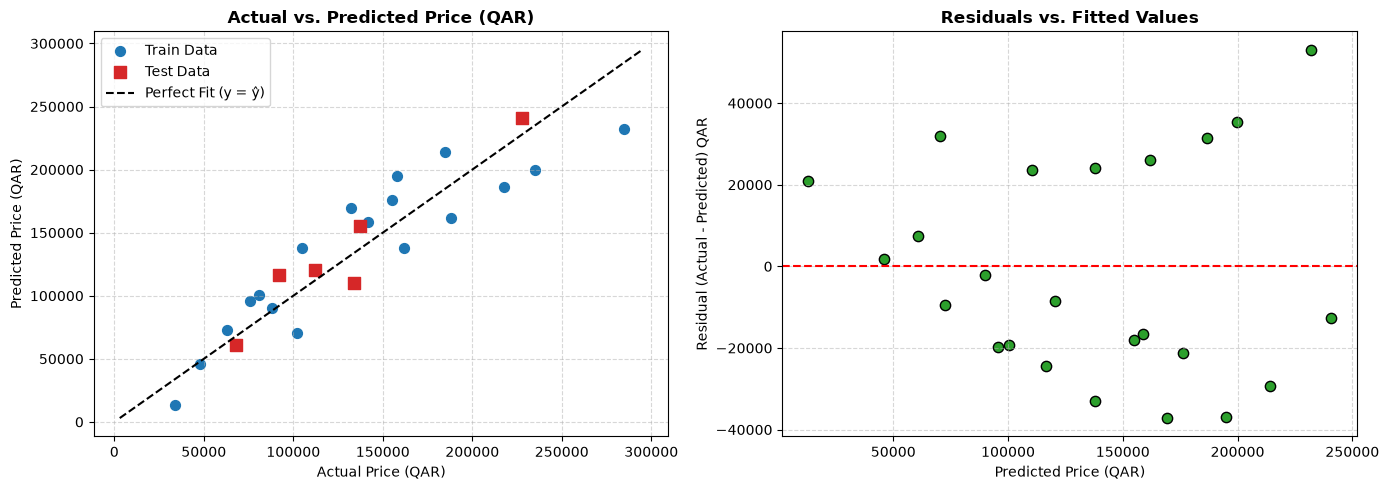

In [7]:
# Step 7: Residual plots
y_pred_all = model_lr.predict(X)
residuals_all = y - y_pred_all

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual vs Predicted
ax1.scatter(y_train, model_lr.predict(X_train), color='#1f77b4', s=50, label='Train Data')
ax1.scatter(y_test, y_pred_test, color='#d62728', s=70, marker='s', label='Test Data')
min_val = min(y.min(), y_pred_all.min()) - 10000
max_val = max(y.max(), y_pred_all.max()) + 10000
ax1.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', label='Perfect Fit (y = ŷ)')
ax1.set_title('Actual vs. Predicted Price (QAR)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Actual Price (QAR)')
ax1.set_ylabel('Predicted Price (QAR)')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# Plot 2: Residuals vs Predicted
ax2.scatter(y_pred_all, residuals_all, color='#2ca02c', s=55, edgecolors='k')
ax2.axhline(0, color='red', linestyle='--', linewidth=1.5)
ax2.set_title('Residuals vs. Fitted Values', fontsize=12, fontweight='bold')
ax2.set_xlabel('Predicted Price (QAR)')
ax2.set_ylabel('Residual (Actual - Predicted) QAR')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Section 7: Practical Used Car Price Estimator

Let's estimate the fair market price for two used cars on Qatar Living:
- **Car 1:** 3-year-old Toyota Prado with $60,000$ km and $4.0\text{L}$ engine.
- **Car 2:** 6-year-old Toyota Camry with $105,000$ km and $2.5\text{L}$ engine.


In [8]:
# Step 8: Price estimation for sample inquiries
sample_cars = np.array([
    [3,  60000, 4.0],  # 3-yr old, 60k km, 4.0L V6 (e.g. Prado)
    [6, 105000, 2.5]   # 6-yr old, 105k km, 2.5L 4-cyl (e.g. Camry)
])

pred_prices = model_lr.predict(sample_cars)

labels = ["3-year-old Toyota Prado (4.0L, 60,000 km)", "6-year-old Toyota Camry (2.5L, 105,000 km)"]

print("=== Estimated Market Prices (Qatar Living Benchmark) ===")
for label, price in zip(labels, pred_prices):
    print(f"{label}: {price:,.0f} QAR")


=== Estimated Market Prices (Qatar Living Benchmark) ===
3-year-old Toyota Prado (4.0L, 60,000 km): 146,879 QAR
6-year-old Toyota Camry (2.5L, 105,000 km): 47,959 QAR


## Section 8: Key Takeaways

1. **Scikit-Learn Workflow:** Create model with `LinearRegression()`, fit with `.fit(X_train, y_train)`, and predict with `.predict(X_test)`.
2. **Train/Test Splitting:** Essential for evaluating how well a model generalizes to new data.
3. **Metrics Hierarchy:**
   - Use **MAE** when communicating results in simple, interpretable currency units (QAR).
   - Use **RMSE** when large prediction errors are particularly costly.
   - Use **$R^2$** to measure overall percentage of variance explained.
4. **Next Step:** In Notebook 06, we discover how **Regularization (Ridge and Lasso)** prevents models from placing excessively large weights on individual features.